In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ctmc_likelihoods = pd.read_csv("../data/simulation/bdt_ctmc/emperical_proof_data/tree_likelihoods.txt", header=None)
ctmc_likelihoods

,0
0,26.477148
1,39.314702
2,102.045583
3,30.029643
4,-4.846653
...,...
95,-11.984641
96,109.619368
97,50.221941
98,-4.554459


In [3]:
cstm_likelihoods = pd.read_csv("../data/simulation/bdt_ctmc/emperical_proof_data/tree_likelihoods_cstm.txt", header=None).iloc[:, 0:8]
cstm_likelihoods

,0,1,2,3,4,5,6,7
0,25.738155,23.716319,26.450753,26.487837,26.540991,26.496364,26.463487,26.477292
1,28.029545,31.859715,38.501961,38.796432,39.206174,39.279918,39.292917,39.317530
2,68.347142,88.704421,99.060034,101.328622,101.693402,101.920666,102.016580,102.041995
3,26.415509,29.760712,30.759414,30.275677,30.337748,30.062937,30.034437,30.026597
4,-4.914235,-4.866431,-4.860990,-4.851068,-4.847442,-4.846769,-4.846733,-4.846695
...,...,...,...,...,...,...,...,...
95,-12.450599,-12.533832,-11.866036,-11.985290,-12.004357,-11.982901,-11.983402,-11.983865
96,92.529256,103.840193,109.446617,110.047655,109.273033,109.558477,109.594372,109.618634
97,49.130236,49.664297,50.010326,50.038466,50.150896,50.217136,50.219262,50.221016
98,-4.574790,-5.800848,-4.273754,-4.376061,-4.480965,-4.530547,-4.546243,-4.554914


In [4]:
errors = pd.DataFrame(np.abs(ctmc_likelihoods.to_numpy() - cstm_likelihoods.to_numpy()))
errors

,0,1,2,3,4,5,6,7
0,0.738993,2.760829,0.026395,0.010689,0.063843,0.019216,0.013661,0.000143
1,11.285156,7.454987,0.812741,0.518270,0.108528,0.034784,0.021785,0.002828
2,33.698441,13.341162,2.985548,0.716960,0.352180,0.124916,0.029003,0.003588
3,3.614134,0.268931,0.729771,0.246034,0.308105,0.033293,0.004794,0.003046
4,0.067582,0.019778,0.014337,0.004415,0.000789,0.000116,0.000080,0.000042
...,...,...,...,...,...,...,...,...
95,0.465958,0.549191,0.118605,0.000649,0.019716,0.001740,0.001239,0.000776
96,17.090112,5.779175,0.172751,0.428287,0.346335,0.060892,0.024997,0.000734
97,1.091705,0.557644,0.211615,0.183476,0.071045,0.004805,0.002679,0.000925
98,0.020332,1.246390,0.280704,0.178398,0.073494,0.023912,0.008216,0.000455


In [5]:
delta_ts = [5, 10, 25, 50, 100, 500, 1000, 10000]

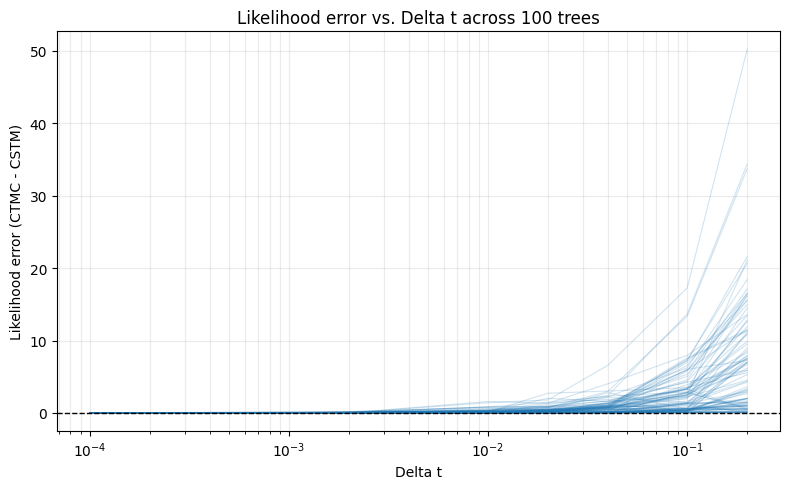

In [6]:
delta_t_values = 1 / np.asarray(delta_ts, dtype=float)
sort_order = np.argsort(delta_t_values)
delta_t_values = delta_t_values[sort_order]

fig, ax = plt.subplots(figsize=(8, 5))
for tree_errors in errors.to_numpy():
    ax.plot(delta_t_values, tree_errors[sort_order], color="tab:blue", alpha=0.2, linewidth=0.8)

ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set_xscale("log")
ax.set_xlabel("Delta t")
ax.set_ylabel("Likelihood error (CTMC - CSTM)")
ax.set_title("Likelihood error vs. Delta t across 100 trees")
ax.grid(True, which="both", alpha=0.25)
fig.tight_layout()
plt.show()

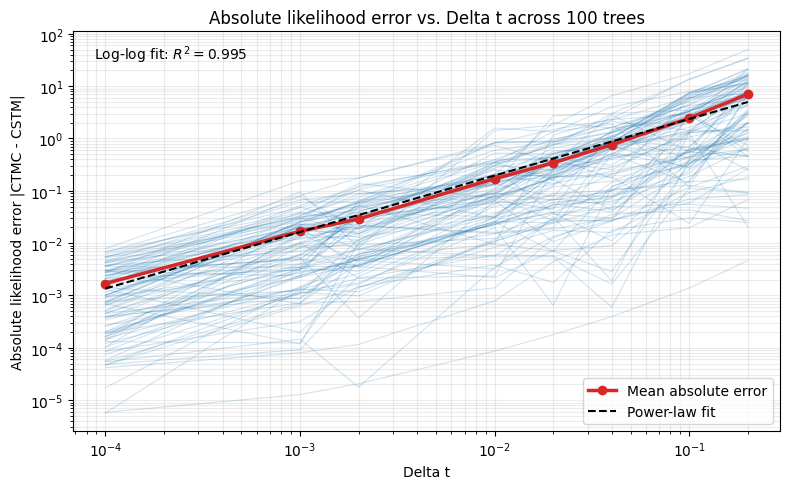

In [7]:
log_delta_t_values = 1 / np.asarray(delta_ts, dtype=float)
log_sort_order = np.argsort(log_delta_t_values)
log_delta_t_values = log_delta_t_values[log_sort_order]
error_values = errors.to_numpy()[:, log_sort_order]
mean_errors = error_values.mean(axis=0)

log_x = np.log10(log_delta_t_values)
log_mean_errors = np.log10(mean_errors)
slope, intercept = np.polyfit(log_x, log_mean_errors, 1)
log_fit = slope * log_x + intercept
r_squared = 1 - np.sum((log_mean_errors - log_fit) ** 2) / np.sum((log_mean_errors - log_mean_errors.mean()) ** 2)

fig, ax = plt.subplots(figsize=(8, 5))
for tree_errors in error_values:
    positive = tree_errors > 0
    ax.loglog(log_delta_t_values[positive], tree_errors[positive], color="tab:blue", alpha=0.2, linewidth=0.8)

ax.loglog(log_delta_t_values, mean_errors, color="tab:red", marker="o", linewidth=2.5, label="Mean absolute error")
ax.loglog(log_delta_t_values, 10 ** log_fit, color="black", linestyle="--", linewidth=1.5, label="Power-law fit")
ax.text(0.03, 0.97, f"Log-log fit: $R^2 = {r_squared:.3f}$", transform=ax.transAxes, va="top")
ax.set_xlabel("Delta t")
ax.set_ylabel("Absolute likelihood error |CTMC - CSTM|")
ax.set_title("Absolute likelihood error vs. Delta t across 100 trees")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


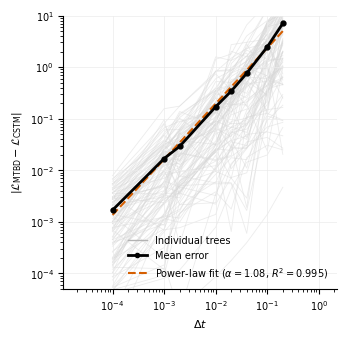

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --------------------------------------------------
# Data preparation
# --------------------------------------------------

inverse_delta_t = 1 / np.asarray(delta_ts, dtype=float)

order = np.argsort(inverse_delta_t)

inverse_delta_t = inverse_delta_t[order]

error_values = errors.to_numpy()[:, order]

mean_errors = error_values.mean(axis=0)

# --------------------------------------------------
# Power-law fit
# --------------------------------------------------

log_x = np.log10(inverse_delta_t)

log_y = np.log10(mean_errors)

slope, intercept = np.polyfit(log_x, log_y, 1)

fit_values = 10 ** (slope * log_x + intercept)

r_squared = (
    1
    - np.sum((log_y - (slope * log_x + intercept)) ** 2)
    / np.sum((log_y - log_y.mean()) ** 2)
)

# --------------------------------------------------
# Nature-style formatting
# --------------------------------------------------

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax = plt.subplots(
    figsize=(3.5, 3.5)
)

# --------------------------------------------------
# Individual trees
# --------------------------------------------------

for tree_errors in error_values:

    positive = tree_errors > 0

    ax.loglog(
        inverse_delta_t[positive],
        tree_errors[positive],
        color="0.85",
        linewidth=0.6,
        alpha=0.5,
        zorder=1,
    )

# --------------------------------------------------
# Mean curve
# --------------------------------------------------

ax.loglog(
    inverse_delta_t,
    mean_errors,
    color="black",
    linewidth=2.0,
    marker="o",
    markersize=3.5,
    zorder=3,
)

# --------------------------------------------------
# Power-law fit
# --------------------------------------------------

ax.loglog(
    inverse_delta_t,
    fit_values,
    color="#D55E00",
    linestyle="--",
    linewidth=1.5,
    zorder=2,
)

# --------------------------------------------------
# Force equal log-scale aspect ratio
# (1 decade on x = 1 decade on y)
# --------------------------------------------------

xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

x_decades = np.log10(xmax) - np.log10(xmin)
y_decades = np.log10(ymax) - np.log10(ymin)

if x_decades > y_decades:

    center = (
        np.log10(ymin)
        + np.log10(ymax)
    ) / 2

    ymin = 10 ** (center - x_decades / 2)
    ymax = 10 ** (center + x_decades / 2)

    ax.set_ylim(ymin, ymax)

else:

    center = (
        np.log10(xmin)
        + np.log10(xmax)
    ) / 2

    xmin = 10 ** (center - y_decades / 2)
    xmax = 10 ** (center + y_decades / 2)

    ax.set_xlim(xmin, xmax)

ax.set_aspect("equal", adjustable="box")

# --------------------------------------------------
# Axes
# --------------------------------------------------

ax.set_xlabel(r"$\Delta t$")

ax.set_ylabel(
    r"$|\mathcal{L}_{\mathrm{MTBD}}-\mathcal{L}_{\mathrm{CSTM}}|$"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    which="major",
    color="0.92",
    linewidth=0.5,
)

# --------------------------------------------------
# Legend
# --------------------------------------------------

legend_elements = [
    Line2D(
        [0],
        [0],
        color="0.7",
        lw=1,
        label="Individual trees",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        lw=2,
        marker="o",
        markersize=3,
        label="Mean error",
    ),
    Line2D(
        [0],
        [0],
        color="#D55E00",
        lw=1.5,
        linestyle="--",
        label=(
            rf"Power-law fit "
            rf"($\alpha={slope:.2f}$, "
            rf"$R^2={r_squared:.3f}$)"
        ),
    ),
]

ax.legend(
    handles=legend_elements,
    frameon=False,
    loc="lower right",
)

ax.set_xlim(5e-5, 5e-1)
ax.set_ylim(5e-5, 1e1)

# ax.set_aspect("equal", adjustable="box")
ax.set_box_aspect(1)

fig.tight_layout()

plt.savefig(
    "likelihood_error_scaling.pdf",
    bbox_inches="tight",
)

plt.savefig(
    "likelihood_error_scaling.svg",
    bbox_inches="tight",
)

plt.show()